# 🏆 Comment Category Prediction Challenge: A Deep Dive into Toxic Discourse
**Author:** Sadaan Baksh | **Course:** Data Science Diploma (MLP Project)

## Overview
In this notebook, we tackle the multi-class classification of online comments into four hierarchical categories:
* **0:** Civil / normal discussion
* **1:** Hate / derogatory speech
* **2:** Personal attacks / hostile arguing
* **3:** Violence, threats, killing, physical harm

**Our Evaluation Metric:** Macro-F1 Score.

### The Challenge
Early modeling revealed that while Classes 0, 1, and 2 are relatively easy to separate, **Class 3 (Violence)** suffers from terrible recall due to semantic overlap with aggressive political speech (Class 1 & 2). In this project, we move beyond basic modeling to deeply understand the *linguistic blueprint* of Class 3 and engineer a custom pipeline to capture it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import re
import gc
import time
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn & Modeling (Strictly adhering to project constraints)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression

# Advanced Boosting
import lightgbm as lgb
from scipy.sparse import hstack, csr_matrix

# Set aesthetic parameters for professional Kaggle Notebook style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_context("notebook", font_scale=1.1)

# Load Data
train = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/test.csv')
sample = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/Sample.csv')

print(f"Train shape: {train.shape} | Test shape: {test.shape}")

Train shape: (198000, 15) | Test shape: (102000, 14)


## 🔍 1. Exploratory Data Analysis: The Blueprint of Class 3
Before throwing algorithms at the problem, we must understand the data. By isolating the 5,469 Class 3 (Violence) comments, a distinct mathematical blueprint emerges. 

1. **The "Big Six"**: Violence in this dataset relies heavily on overt terminology.
2. **Pronoun Targeting**: Violence is rarely abstract; it is targeted at "you" or "they".
3. **Elongations & Metadata**: Emotional escalation is signaled by character elongation ("diiieee"), whereas standard aggressive markers like ALL CAPS are surprisingly rare.

In [2]:
train.dtypes

created_date    object
post_id          int64
emoticon_1       int64
emoticon_2       int64
emoticon_3       int64
upvote           int64
downvote         int64
if_1             int64
if_2             int64
race            object
religion        object
gender          object
disability        bool
comment         object
label            int64
dtype: object

In [3]:
print("--- Null values before filling ---")
null_counts = train.isna().sum()
print(null_counts[null_counts > 0]) 

# Fill empty comments with ""
# Fill empty race, gender, religion columns with "Unknown"
train['comment'] = train['comment'].fillna('')
train[['race', 'religion', 'gender']] = train[['race', 'religion', 'gender']].fillna("unknown")

test['comment'] = test['comment'].fillna('')
test[['race', 'religion', 'gender']] = test[['race', 'religion', 'gender']].fillna("unknown")

print("\n--- Null values after filling ---")
print(train.isnull().sum().sum()) 

--- Null values before filling ---
race        145423
religion    145423
gender      145423
comment          1
dtype: int64

--- Null values after filling ---
0


FEATURE ENGINEERING FOR EDA:

In [4]:
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# ==============================================================================
# 1. THREAD / CONTEXTUAL FEATURES (Applied to both Train & Test)
# ==============================================================================
print("Generating Thread Features...")

# Temporarily combine to get global thread statistics
test_temp = test.copy()
test_temp['label'] = np.nan 
all_data = pd.concat([train, test_temp], axis=0, ignore_index=True)

thread_stats = all_data.groupby('post_id').agg({
    'comment': 'count',              # Thread volume
    'upvote': ['mean', 'std', 'sum'], 
    'downvote': ['mean', 'std', 'sum']
})

thread_stats.columns = [
    'thread_vol', 
    'thread_up_mean', 'thread_up_std', 'thread_up_sum', 
    'thread_down_mean', 'thread_down_std', 'thread_down_sum'
]
thread_stats = thread_stats.reset_index()

# Advanced thread metrics
thread_stats['thread_engagement'] = thread_stats['thread_up_sum'] + thread_stats['thread_down_sum']
thread_stats['thread_negativity_ratio'] = thread_stats['thread_down_sum'] / (thread_stats['thread_up_sum'] + 1)

# Merge back to train and test
train = train.merge(thread_stats, on='post_id', how='left')
test = test.merge(thread_stats, on='post_id', how='left')

# Fill NaN std deviations (happens when thread_vol == 1)
fill_zero_cols = ['thread_up_std', 'thread_down_std']
train[fill_zero_cols] = train[fill_zero_cols].fillna(0)
test[fill_zero_cols] = test[fill_zero_cols].fillna(0)


# ==============================================================================
# 2. TERM DICTIONARIES (Cleaned & Deduplicated)
# ==============================================================================
violent_terms = list(set([
    'kill', 'die', 'death', 'shoot', 'fire', 'killing', 'dead', 'hang', 'hit',
    'burn', 'murder', 'rid', 'shot', 'punch', 'shooting', 'guns', 'suicide',
    'bomb', 'gun', 'fired', 'kick', 'knife', 'killed', 'torture', 'bullet',
    'slap', 'destroy', 'stab', 'killer', 'murderer', 'nuke', 'pulverize', 
    'holocaust', 'missile', 'blow up', 'poison', 'dumping body', 'strike fear', 
    'jail', 'prison', 'lock her up', 'prosecute', 'death penalty', 'terrorist', 
    'meth dealer', 'war zone', 'sanctuary status'
]))

moral_terms = ["deserve", "should", "solution", "need to", "have to", "all of them"]

group_terms = list(set([
    'muslim', 'jew', 'jewish', 'christian', 'catholic', 'women', 'men', 'woman',
    'female', 'male', 'black', 'white', 'asian', 'immigrant', 'refugee',
    'gay', 'lesbian', 'native', 'indian', 'buddhist', 'infidel', 'haram', 
    'devout', 'religious', 'native american', 'ethnic', 'liberal', 'left winger',
    'progressive', 'theo-con', 'trump', 'blm', 'ku klux klan', 'neo-nazi',
    'white supremacist', 'homosexual', 'asylum seeker'
]))

personal_attack = list(set([
    "lunatic", "looney", "mindless drivel", "ignorant", "ignorance",
    "stupid", "foolish", "gullible", "hallucination", "mental condition",
    "greedy", "criminal", "ethically challenged", "corruption", "rot",
    "cultist", "sheep", "loudmouth", "vampire", "traitor", 
    "troll", "arrogant", "liar", "lying", "weak", "victim complex",
    "mom's basement", "strawman", "hypocrite"
]))


# ==============================================================================
# 3. UNIFIED FEATURE ENGINEERING FUNCTION
# ==============================================================================
def add_term_indicator_columns(df, terms, prefix):
    for term in terms:
        col_name = f"{prefix}_{term}"
        pattern = rf"(?i)\b{re.escape(term)}\b" # Added \b to prevent partial word matches (e.g. "skill" for "kill")
        df[col_name] = df["comment"].str.contains(pattern, regex=True, na=False).astype(int)
    return df


def engineer_features(df):
    """Applies all text cleaning, structural extraction, and EDA insights globally."""
    df = df.copy()
    
    # Fill missing comments
    df['comment'] = df['comment'].fillna('Null').astype(str)
    
    # --- Structural Meta-Features ---
    df["text_len"] = df["comment"].str.len()
    df["word_count"] = df["comment"].str.split().str.len()
    df["caps_ratio"] = df["comment"].apply(lambda x: sum(1 for c in x if c.isupper()) / max(len(x), 1))
    df["question_marks"] = df["comment"].str.count(r"\?")
    df["exclamations"] = df["comment"].str.count(r"!")
    
    # --- Text Preprocessing ---
    # Squash elongations: "I will kiiillll youuuu" -> "I will kill you"
    df['clean_comment'] = df['comment'].apply(lambda x: re.sub(r'(.)\1{2,}', r'\1', x))
    
    # CLASS 3 EDA 
    df['has_kill'] = df['clean_comment'].str.contains('kill', case=False).astype(int)
    df['has_shoot'] = df['clean_comment'].str.contains(r'shoot|shot', case=False).astype(int)
    df['has_death'] = df['clean_comment'].str.contains(r'death|dead', case=False).astype(int)
    df['has_gun'] = df['clean_comment'].str.contains(r'\bgun\b', case=False).astype(int)
    df['has_die'] = df['clean_comment'].str.contains(r'\bdie\b', case=False).astype(int)
    
    df['has_you'] = df['clean_comment'].str.contains(r'\b(you|your|ur)\b', case=False).astype(int)
    df['has_they'] = df['clean_comment'].str.contains(r'\b(they|them|their)\b', case=False).astype(int)
    
    lethal_columns = ['has_kill', 'has_shoot', 'has_death', 'has_gun', 'has_die']
    df['has_any_lethal'] = df[lethal_columns].max(axis=1)
    df['has_any_target'] = df[['has_you', 'has_they']].max(axis=1)
    df['targeted_violence'] = ((df['has_any_lethal'] == 1) & (df['has_any_target'] == 1)).astype(int)
    
    
    # CLASS 1 EDA
    df['has_race'] = df['clean_comment'].str.contains(r'\b(white|black|asian|hispanic)\b', case=False).astype(int)
    df['has_religion'] = df['clean_comment'].str.contains(r'\b(muslim|islam|jew|jewish|christian)\b', case=False).astype(int)
    df['has_gender_sex'] = df['clean_comment'].str.contains(r'\b(women|men|gay|lgbt|homo|trans)\b', case=False).astype(int)
    df['has_group_pronoun'] = df['clean_comment'].str.contains(r'\b(they|them|their|those)\b', case=False).astype(int)
    df['has_any_identity'] = df[['has_race', 'has_religion', 'has_gender_sex']].max(axis=1)
    df['othering_flag'] = ((df['has_any_identity'] == 1) & (df['has_group_pronoun'] == 1)).astype(int)
    
    # CLASS 2 EDA
    df['has_intelligence_attack'] = df['clean_comment'].str.contains(r'\b(stupid|idiot|dumb|moron|ignorant)\b', case=False).astype(int)
    df['has_character_attack'] = df['clean_comment'].str.contains(r'\b(hypocrite|liar|troll|clown|pathetic)\b', case=False).astype(int)
    df['has_you'] = df['clean_comment'].str.contains(r'\b(you|your|ur)\b', case=False).astype(int)
    df['has_you_are'] = df['clean_comment'].str.contains(r'\b(you are|youre)\b', case=False).astype(int)
    df['has_politics'] = df['clean_comment'].str.contains(r'\b(trump|president|government|liberal|conservative|republican|democrat)\b', case=False).astype(int)
    df['has_demographics'] = df['clean_comment'].str.contains(r'\b(white|black|muslim|islam|jew|jewish|gay|lgbt|women|men)\b', case=False).astype(int)

    # Extract numerical structural features for the Correlation Matrix
    df['word_count'] = df['clean_comment'].apply(lambda x: len(x.split()))
    df['char_length'] = df['clean_comment'].apply(len)
    df['caps_ratio'] = df['clean_comment'].apply(lambda x: sum(1 for c in x if c.isupper()) / (len(x) + 1))
    df['exclamation_count'] = df['clean_comment'].apply(lambda x: x.count('!'))
    df['question_count'] = df['clean_comment'].apply(lambda x: x.count('?'))
    
    # --- Broad Term Indicators ---
    df = add_term_indicator_columns(df, terms=violent_terms, prefix="v")
    df = add_term_indicator_columns(df, terms=moral_terms, prefix="m")
    df = add_term_indicator_columns(df, terms=group_terms, prefix="g")
    df = add_term_indicator_columns(df, terms=personal_attack, prefix="p")

    return df


# ==============================================================================
# 4. EXECUTE PIPELINE & DEFINE COLUMN TRANSFORMER
# ==============================================================================
print("Engineering Features for Train and Test sets...")

X_full = engineer_features(train)
X_test = engineer_features(test)
y = train['label']

# Dynamically gather all numerical features generated by the engineer_features function
thread_features = [
    'thread_vol', 'thread_up_mean', 'thread_up_std', 
    'thread_down_mean', 'thread_down_std', 
    'thread_engagement', 'thread_negativity_ratio'
]

base_num_features = [
    'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', "if_1", "if_2", 
    "disability", "text_len", "word_count", "question_marks", "exclamations", "caps_ratio",
    
    # Include all our new EDA interaction features!
    "total_violent_words", "violence_density", "count_you", "count_they", "targeted_violence",
    "has_any_identity", "has_group_pronoun", "othering_flag", 
    "total_insult_words", "count_you_are", "direct_attack_flag", "has_politics"
] + thread_features

term_feature_cols = [c for c in X_full.columns if c.startswith(("v_", "m_", "g_", "p_"))]

num_features = base_num_features + term_feature_cols
cat_features = ["race", "religion", "gender"]

print(f"Total Numerical Features defined: {len(num_features)}")

feature_encoder = ColumnTransformer(
    transformers=[
        ("num_scaler", StandardScaler(), num_features), 
        ("cats", OneHotEncoder(handle_unknown="ignore"), cat_features)
    ],
    remainder='drop' # Drops columns not explicitly listed (like 'comment', 'clean_comment', 'post_id')
)

Generating Thread Features...
Engineering Features for Train and Test sets...
Total Numerical Features defined: 151


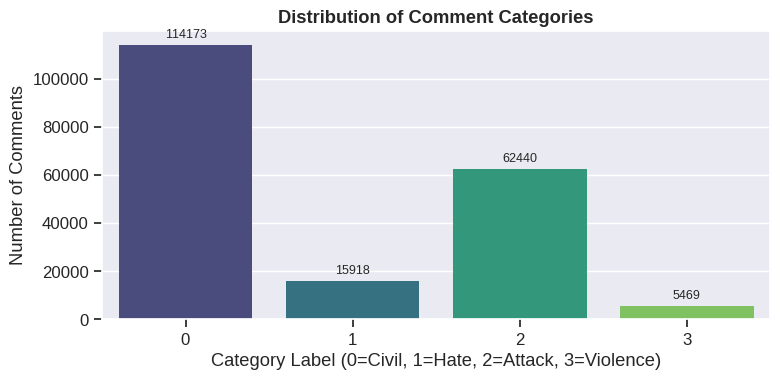

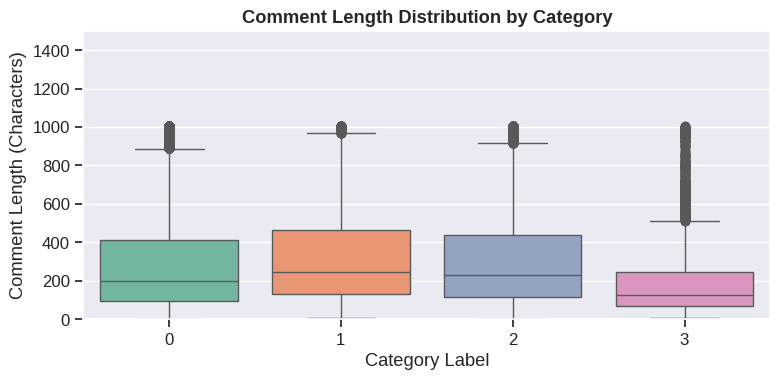

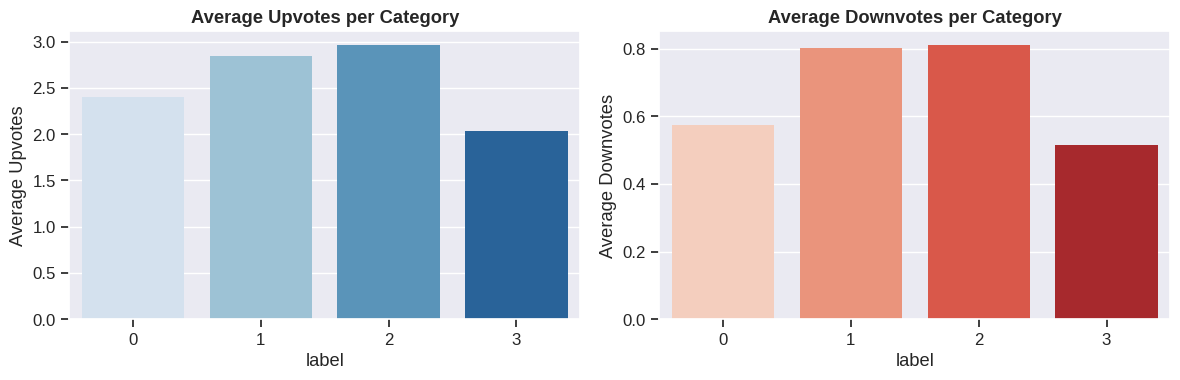

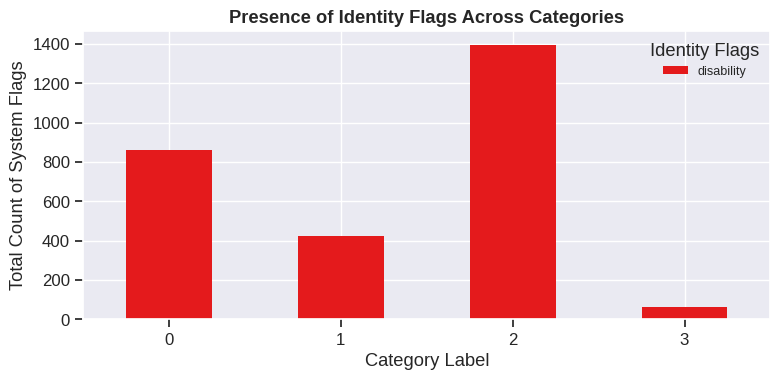

In [5]:

# ==========================================
# 1. Target Variable Distribution
# ==========================================
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=train, x='label', palette='viridis')
plt.title('Distribution of Comment Categories', fontweight='bold')
plt.ylabel('Number of Comments')
plt.xlabel('Category Label (0=Civil, 1=Hate, 2=Attack, 3=Violence)')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()

# ==========================================
# 2. Text Length vs Category
# ==========================================
train['text_length'] = train['comment'].astype(str).str.len()

plt.figure(figsize=(8, 4))
sns.boxplot(data=train, x='label', y='text_length', palette='Set2')
plt.title('Comment Length Distribution by Category', fontweight='bold')
plt.ylim(0, 1500) 
plt.xlabel('Category Label')
plt.ylabel('Comment Length (Characters)')
plt.tight_layout()
plt.show()

# ==========================================
# 3. User Engagement: Upvotes vs Downvotes
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=train, x='label', y='upvote', ax=axes[0], palette='Blues', errorbar=None)
axes[0].set_title('Average Upvotes per Category', fontweight='bold')
axes[0].set_ylabel('Average Upvotes')

sns.barplot(data=train, x='label', y='downvote', ax=axes[1], palette='Reds', errorbar=None)
axes[1].set_title('Average Downvotes per Category', fontweight='bold')
axes[1].set_ylabel('Average Downvotes')

plt.tight_layout()
plt.show()

# ==========================================
# 4. Identity Flags (Race, Religion, Gender, Disability)
# ==========================================
identity_cols = ['race', 'religion', 'gender', 'disability']
identity_summary = train.groupby('label')[identity_cols].sum()

identity_summary.plot(kind='bar', stacked=False, figsize=(8, 4), colormap='Set1')
plt.title('Presence of Identity Flags Across Categories', fontweight='bold')
plt.xlabel('Category Label')
plt.ylabel('Total Count of System Flags')
plt.xticks(rotation=0)
plt.legend(title='Identity Flags', fontsize=9)
plt.tight_layout()
plt.show()

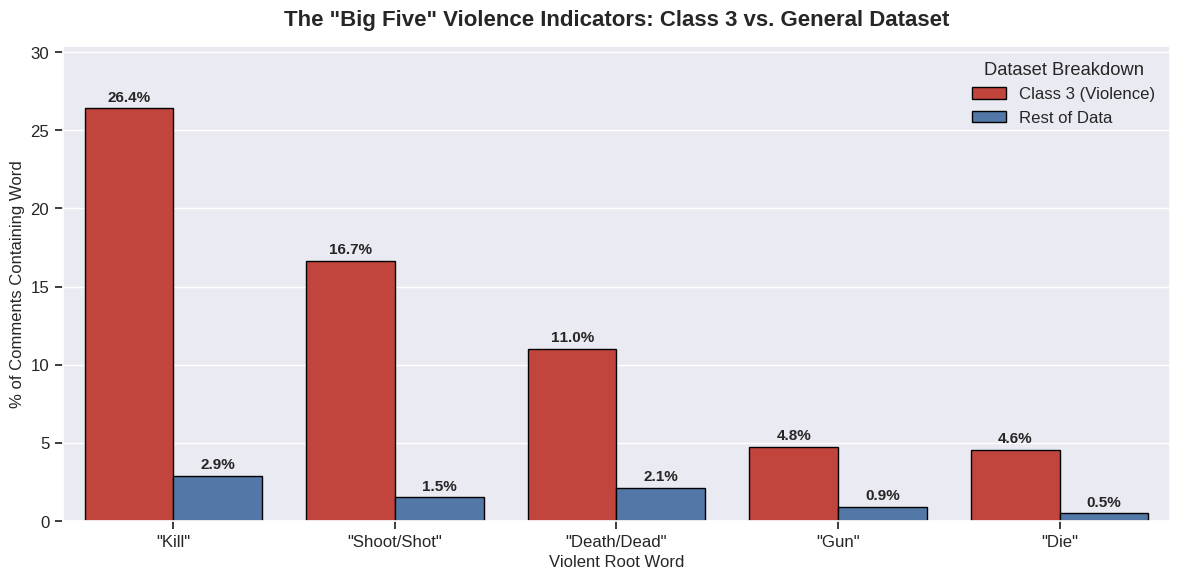

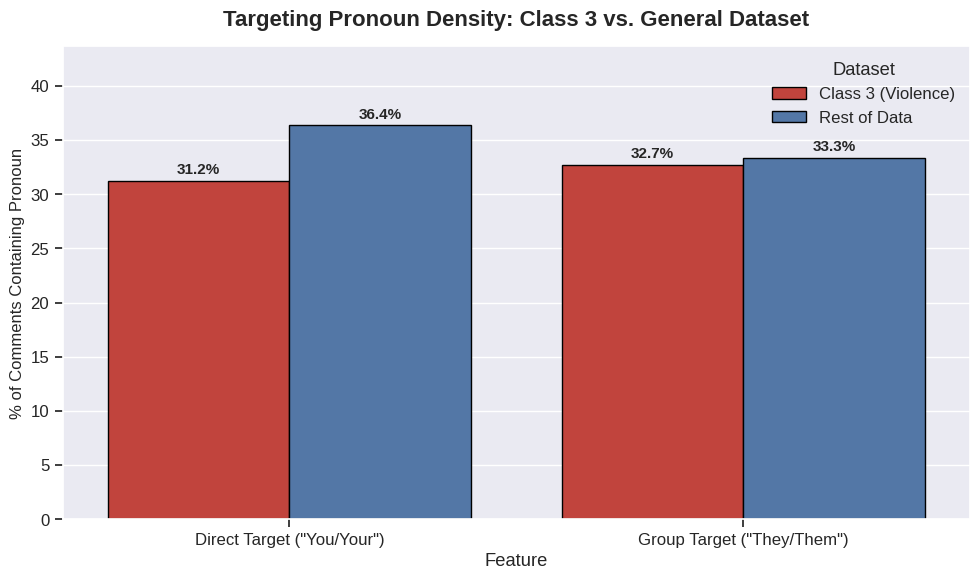

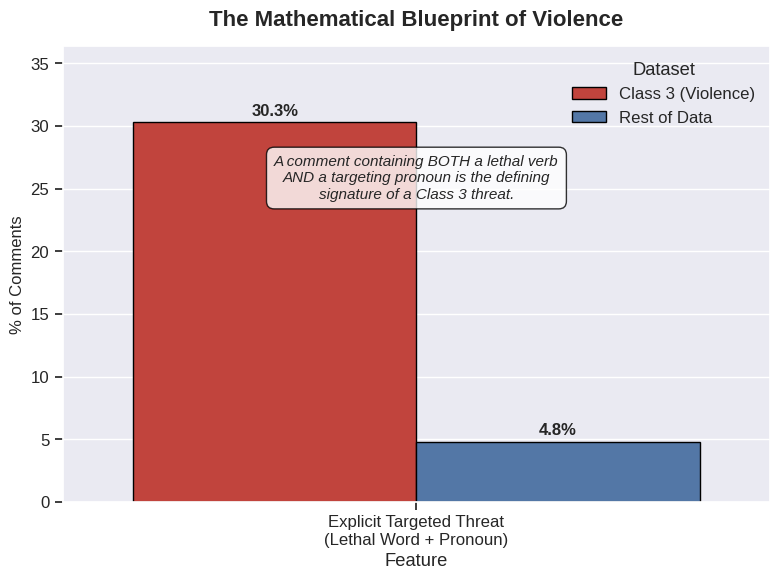

In [6]:
# Split the data into Class 3 and "Rest of Dataset" for comparison
c3 = X_full[X_full['label'] == 3]
rest = X_full[X_full['label'] != 3]

# ---------------------------------------------------------
# Visualization 1: The "Big Six" Lethal Lexicon Frequency
# ---------------------------------------------------------
# Prepare data for grouped bar chart
data1 = {
    'Feature': [
        '"Kill"', '"Kill"', 
        '"Shoot/Shot"', '"Shoot/Shot"', 
        '"Death/Dead"', '"Death/Dead"',
        '"Gun"', '"Gun"',
        '"Die"', '"Die"',
    ],
    'Dataset': ['Class 3 (Violence)', 'Rest of Data'] * 5,
    'Percentage': [
        c3['has_kill'].mean() * 100, rest['has_kill'].mean() * 100,
        c3['has_shoot'].mean() * 100, rest['has_shoot'].mean() * 100,
        c3['has_death'].mean() * 100, rest['has_death'].mean() * 100,
        c3['has_gun'].mean() * 100, rest['has_gun'].mean() * 100,
        c3['has_die'].mean() * 100, rest['has_die'].mean() * 100,
    ]
}
df_plot1 = pd.DataFrame(data1)

# Made the figure slightly wider to accommodate 5 categories
plt.figure(figsize=(12, 6))
ax1 = sns.barplot(data=df_plot1, x='Feature', y='Percentage', hue='Dataset', palette=['#d73027', '#4575b4'], edgecolor='black')
plt.title('The "Big Five" Violence Indicators: Class 3 vs. General Dataset', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments Containing Word', fontsize=12)
plt.xlabel('Violent Root Word', fontsize=12)

# Add data labels
for p in ax1.patches:
    if p.get_height() > 0.1: # Only annotate bars with a visible percentage
        ax1.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=11, fontweight='bold')
plt.ylim(0, max(df_plot1['Percentage']) * 1.15)
plt.legend(title='Dataset Breakdown')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Visualization 2: The Targeting Pronoun Overlap
# ---------------------------------------------------------
data2 = {
    'Feature': ['Direct Target ("You/Your")', 'Direct Target ("You/Your")', 'Group Target ("They/Them")', 'Group Target ("They/Them")'],
    'Dataset': ['Class 3 (Violence)', 'Rest of Data', 'Class 3 (Violence)', 'Rest of Data'],
    'Percentage': [
        c3['has_you'].mean() * 100, rest['has_you'].mean() * 100,
        c3['has_they'].mean() * 100, rest['has_they'].mean() * 100
    ]
}
df_plot2 = pd.DataFrame(data2)

plt.figure(figsize=(10, 6))
ax2 = sns.barplot(data=df_plot2, x='Feature', y='Percentage', hue='Dataset', palette=['#d73027', '#4575b4'], edgecolor='black')
plt.title('Targeting Pronoun Density: Class 3 vs. General Dataset', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments Containing Pronoun', fontsize=12)

for p in ax2.patches:
    if p.get_height() > 0:
        ax2.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=11, fontweight='bold')
plt.ylim(0, max(df_plot2['Percentage']) * 1.2)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Visualization 3: The Targeted Threat Flag
# ---------------------------------------------------------
data3 = {
    'Feature': ['Explicit Targeted Threat\n(Lethal Word + Pronoun)', 'Explicit Targeted Threat\n(Lethal Word + Pronoun)'],
    'Dataset': ['Class 3 (Violence)', 'Rest of Data'],
    'Percentage': [
        c3['targeted_violence'].mean() * 100, 
        rest['targeted_violence'].mean() * 100
    ]
}
df_plot3 = pd.DataFrame(data3)

plt.figure(figsize=(8, 6))
ax3 = sns.barplot(data=df_plot3, x='Feature', y='Percentage', hue='Dataset', palette=['#d73027', '#4575b4'], edgecolor='black')
plt.title('The Mathematical Blueprint of Violence', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments', fontsize=12)

# Add custom subtitle/text to explain the insight
plt.text(0, max(df_plot3['Percentage']) * 0.8, 
         "A comment containing BOTH a lethal verb\nAND a targeting pronoun is the defining\nsignature of a Class 3 threat.", 
         ha='center', fontsize=11, style='italic', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

for p in ax3.patches:
    if p.get_height() > 0:
        ax3.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=12, fontweight='bold')
plt.ylim(0, max(df_plot3['Percentage']) * 1.2)
plt.tight_layout()
plt.show()


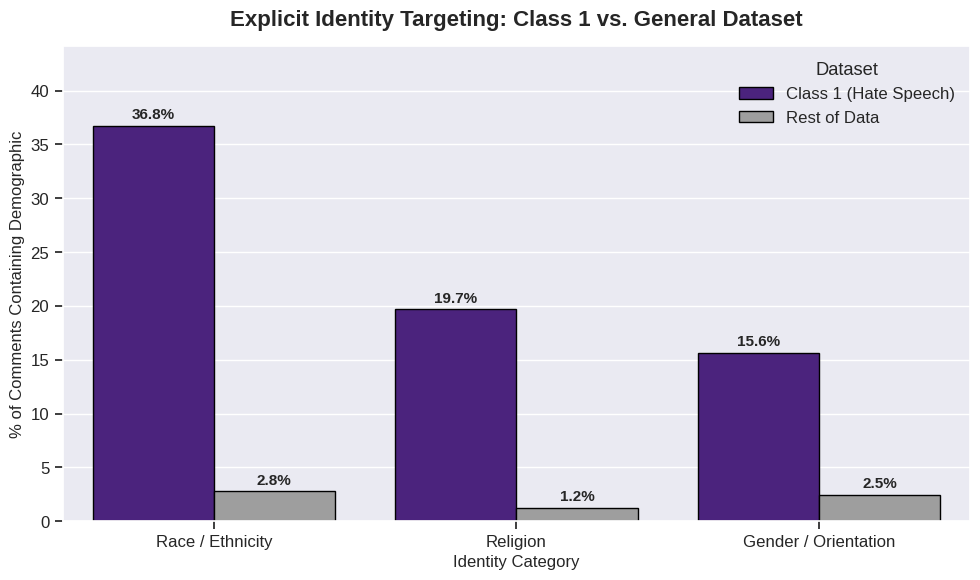

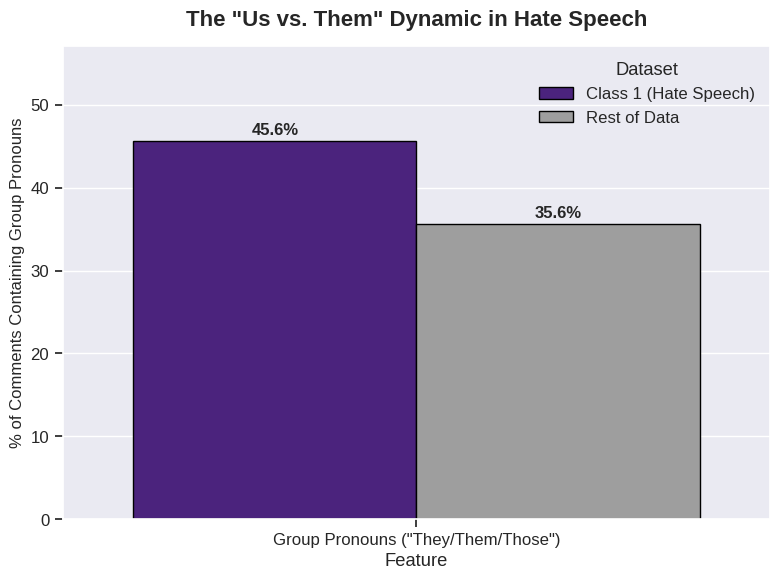

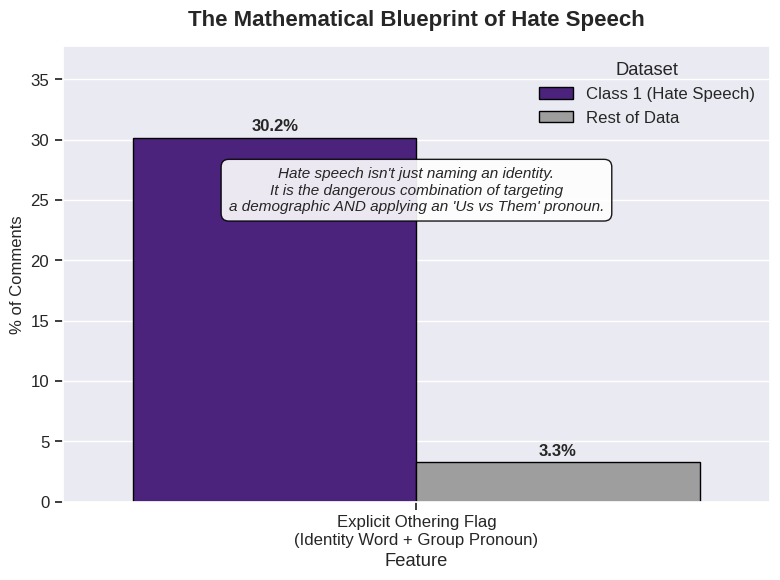

In [7]:
# Split the data into Class 1 and "Rest of Dataset" for comparison
c1 = X_full[X_full['label'] == 1]
rest = X_full[X_full['label'] != 1]

# Set a color palette: Deep Purple for Class 1, Grey for the rest
palette_colors = ['#4a148c', '#9e9e9e']

# ---------------------------------------------------------
# Visualization 1: The Identity Lexicon Frequency
# ---------------------------------------------------------
data1 = {
    'Feature': [
        'Race / Ethnicity', 'Race / Ethnicity', 
        'Religion', 'Religion', 
        'Gender / Orientation', 'Gender / Orientation'
    ],
    'Dataset': ['Class 1 (Hate Speech)', 'Rest of Data'] * 3,
    'Percentage': [
        c1['has_race'].mean() * 100, rest['has_race'].mean() * 100,
        c1['has_religion'].mean() * 100, rest['has_religion'].mean() * 100,
        c1['has_gender_sex'].mean() * 100, rest['has_gender_sex'].mean() * 100
    ]
}
df_plot1 = pd.DataFrame(data1)

plt.figure(figsize=(10, 6))
ax1 = sns.barplot(data=df_plot1, x='Feature', y='Percentage', hue='Dataset', palette=palette_colors, edgecolor='black')
plt.title('Explicit Identity Targeting: Class 1 vs. General Dataset', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments Containing Demographic', fontsize=12)
plt.xlabel('Identity Category', fontsize=12)

# Add data labels
for p in ax1.patches:
    if p.get_height() > 0.5:
        ax1.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=11, fontweight='bold')
plt.ylim(0, max(df_plot1['Percentage']) * 1.2)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Visualization 2: The "Us vs. Them" Dynamic (Pronouns)
# ---------------------------------------------------------
data2 = {
    'Feature': ['Group Pronouns ("They/Them/Those")', 'Group Pronouns ("They/Them/Those")'],
    'Dataset': ['Class 1 (Hate Speech)', 'Rest of Data'],
    'Percentage': [
        c1['has_group_pronoun'].mean() * 100, rest['has_group_pronoun'].mean() * 100
    ]
}
df_plot2 = pd.DataFrame(data2)

plt.figure(figsize=(8, 6))
ax2 = sns.barplot(data=df_plot2, x='Feature', y='Percentage', hue='Dataset', palette=palette_colors, edgecolor='black')
plt.title('The "Us vs. Them" Dynamic in Hate Speech', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments Containing Group Pronouns', fontsize=12)

for p in ax2.patches:
    if p.get_height() > 0.5:
        ax2.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=12, fontweight='bold')
plt.ylim(0, max(df_plot2['Percentage']) * 1.25)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Visualization 3: The "Othering" Blueprint Insight
# ---------------------------------------------------------
data3 = {
    'Feature': ['Explicit Othering Flag\n(Identity Word + Group Pronoun)', 'Explicit Othering Flag\n(Identity Word + Group Pronoun)'],
    'Dataset': ['Class 1 (Hate Speech)', 'Rest of Data'],
    'Percentage': [
        c1['othering_flag'].mean() * 100, 
        rest['othering_flag'].mean() * 100
    ]
}
df_plot3 = pd.DataFrame(data3)

plt.figure(figsize=(8, 6))
ax3 = sns.barplot(data=df_plot3, x='Feature', y='Percentage', hue='Dataset', palette=palette_colors, edgecolor='black')
plt.title('The Mathematical Blueprint of Hate Speech', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments', fontsize=12)

# Add custom subtitle/text to explain the insight
plt.text(0, max(df_plot3['Percentage']) * 0.8, 
         "Hate speech isn't just naming an identity.\nIt is the dangerous combination of targeting\na demographic AND applying an 'Us vs Them' pronoun.", 
         ha='center', fontsize=11, style='italic', bbox=dict(facecolor='white', alpha=0.9, boxstyle='round,pad=0.5'))

for p in ax3.patches:
    if p.get_height() > 0.5:
        ax3.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=12, fontweight='bold')
plt.ylim(0, max(df_plot3['Percentage']) * 1.25)
plt.tight_layout()
plt.show()



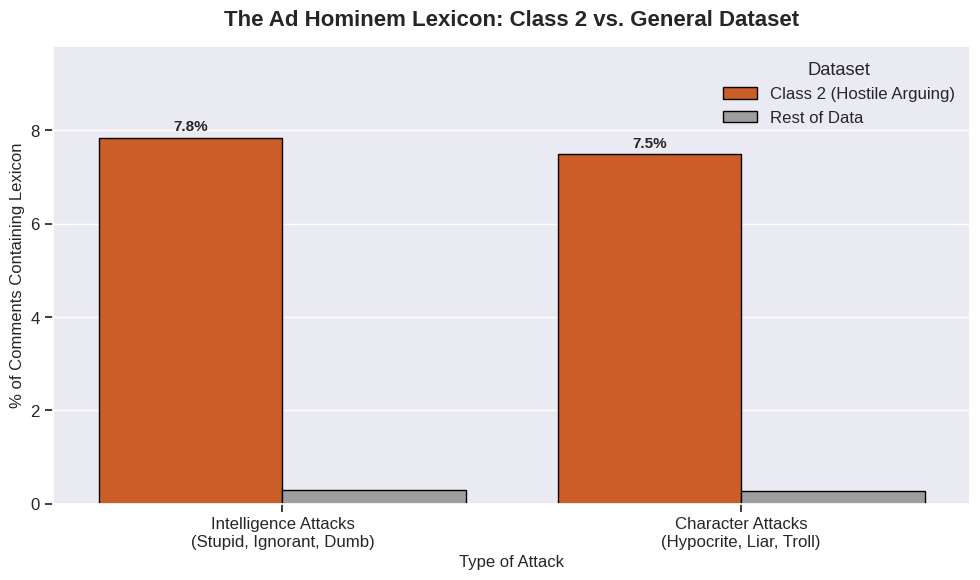

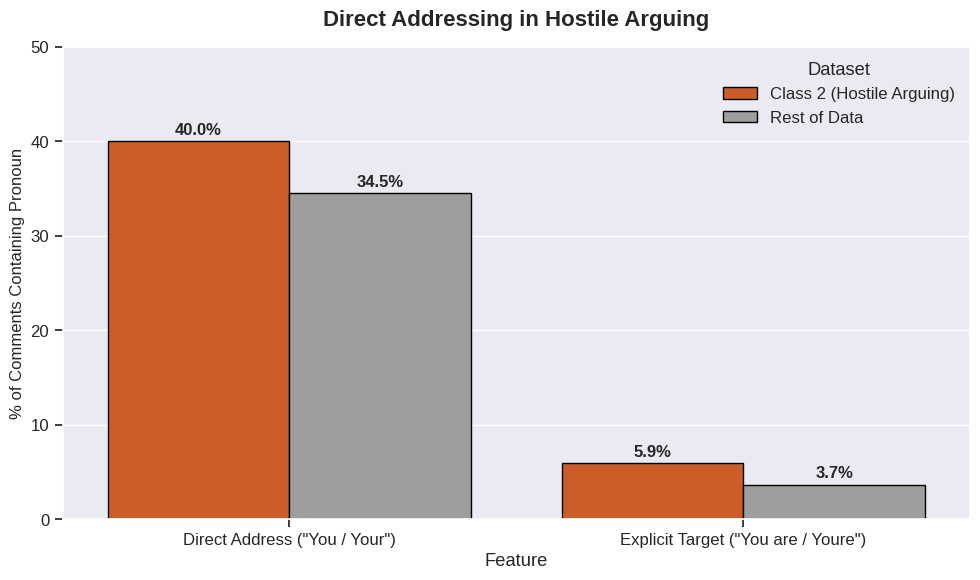

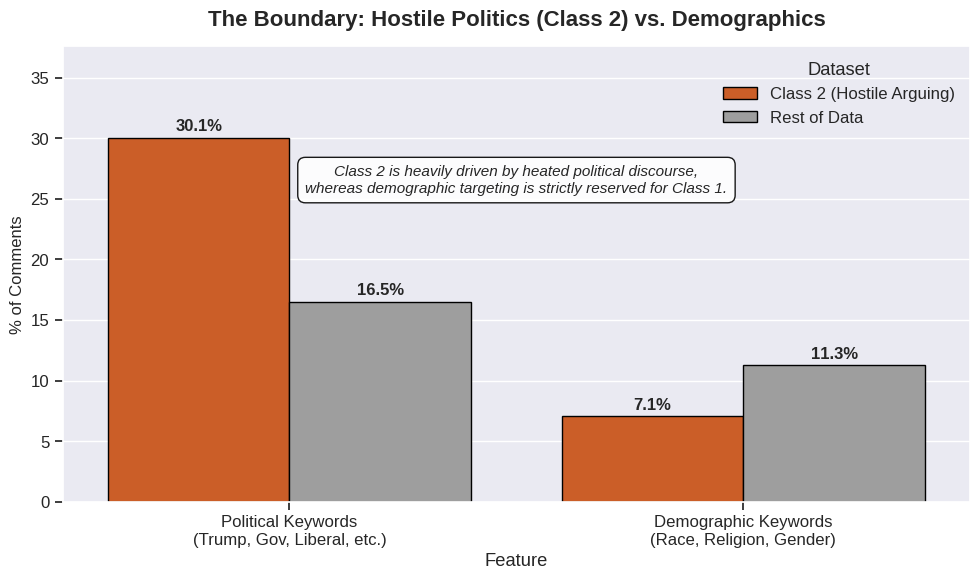

In [8]:
# Split the data into Class 2 and "Rest of Dataset" for comparison
c2 = X_full[X_full['label'] == 2]
rest = X_full[X_full['label'] != 2]

# Set a color palette: Dark Orange for Class 2, Grey for the rest
palette_colors = ['#e6550d', '#9e9e9e']

# ---------------------------------------------------------
# Visualization 1: The Ad Hominem Lexicon Frequency
# ---------------------------------------------------------
data1 = {
    'Feature': [
        'Intelligence Attacks\n(Stupid, Ignorant, Dumb)', 'Intelligence Attacks\n(Stupid, Ignorant, Dumb)', 
        'Character Attacks\n(Hypocrite, Liar, Troll)', 'Character Attacks\n(Hypocrite, Liar, Troll)'
    ],
    'Dataset': ['Class 2 (Hostile Arguing)', 'Rest of Data'] * 2,
    'Percentage': [
        c2['has_intelligence_attack'].mean() * 100, rest['has_intelligence_attack'].mean() * 100,
        c2['has_character_attack'].mean() * 100, rest['has_character_attack'].mean() * 100
    ]
}
df_plot1 = pd.DataFrame(data1)

plt.figure(figsize=(10, 6))
ax1 = sns.barplot(data=df_plot1, x='Feature', y='Percentage', hue='Dataset', palette=palette_colors, edgecolor='black')
plt.title('The Ad Hominem Lexicon: Class 2 vs. General Dataset', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments Containing Lexicon', fontsize=12)
plt.xlabel('Type of Attack', fontsize=12)

# Add data labels
for p in ax1.patches:
    if p.get_height() > 0.5:
        ax1.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=11, fontweight='bold')
plt.ylim(0, max(df_plot1['Percentage']) * 1.25)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Visualization 2: The "Direct Address" Shift
# ---------------------------------------------------------
data2 = {
    'Feature': [
        'Direct Address ("You / Your")', 'Direct Address ("You / Your")',
        'Explicit Target ("You are / Youre")', 'Explicit Target ("You are / Youre")'
    ],
    'Dataset': ['Class 2 (Hostile Arguing)', 'Rest of Data'] * 2,
    'Percentage': [
        c2['has_you'].mean() * 100, rest['has_you'].mean() * 100,
        c2['has_you_are'].mean() * 100, rest['has_you_are'].mean() * 100
    ]
}
df_plot2 = pd.DataFrame(data2)

plt.figure(figsize=(10, 6))
ax2 = sns.barplot(data=df_plot2, x='Feature', y='Percentage', hue='Dataset', palette=palette_colors, edgecolor='black')
plt.title('Direct Addressing in Hostile Arguing', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments Containing Pronoun', fontsize=12)

for p in ax2.patches:
    if p.get_height() > 0.5:
        ax2.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=12, fontweight='bold')
plt.ylim(0, max(df_plot2['Percentage']) * 1.25)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Visualization 3: Hostile Politics vs. Demographic Targeting
# ---------------------------------------------------------
data3 = {
    'Feature': [
        'Political Keywords\n(Trump, Gov, Liberal, etc.)', 'Political Keywords\n(Trump, Gov, Liberal, etc.)',
        'Demographic Keywords\n(Race, Religion, Gender)', 'Demographic Keywords\n(Race, Religion, Gender)'
    ],
    'Dataset': ['Class 2 (Hostile Arguing)', 'Rest of Data'] * 2,
    'Percentage': [
        c2['has_politics'].mean() * 100, rest['has_politics'].mean() * 100,
        c2['has_demographics'].mean() * 100, rest['has_demographics'].mean() * 100
    ]
}
df_plot3 = pd.DataFrame(data3)

plt.figure(figsize=(10, 6))
ax3 = sns.barplot(data=df_plot3, x='Feature', y='Percentage', hue='Dataset', palette=palette_colors, edgecolor='black')
plt.title('The Boundary: Hostile Politics (Class 2) vs. Demographics', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('% of Comments', fontsize=12)

# Add custom subtitle/text to explain the insight
plt.text(0.5, max(df_plot3['Percentage']) * 0.85, 
         "Class 2 is heavily driven by heated political discourse,\nwhereas demographic targeting is strictly reserved for Class 1.", 
         ha='center', fontsize=11, style='italic', bbox=dict(facecolor='white', alpha=0.9, boxstyle='round,pad=0.5'))

for p in ax3.patches:
    if p.get_height() > 0.5:
        ax3.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=12, fontweight='bold')
plt.ylim(0, max(df_plot3['Percentage']) * 1.25)
plt.tight_layout()
plt.show()

# Quick calculation for the EDA plot to show the breakdown of the expanded lexicon
c2_disgust = c2['clean_comment'].str.contains(r'\b(sick|disgusting|pathetic|gross|vile|evil)\b', case=False).mean() * 100
rest_disgust = rest['clean_comment'].str.contains(r'\b(sick|disgusting|pathetic|gross|vile|evil)\b', case=False).mean() * 100

c2_deranged = c2['clean_comment'].str.contains(r'\b(crazy|insane|lunatic|psycho|delusional|deranged)\b', case=False).mean() * 100
rest_deranged = rest['clean_comment'].str.contains(r'\b(crazy|insane|lunatic|psycho|delusional|deranged)\b', case=False).mean() * 100



## 🧪 2. The Modeling Journey: What Failed & Why
To satisfy the scientific rigor of this project, it is important to document negative results.
* **Standard Threshold Tuning:** Initially increased recall for Class 3 but destroyed precision. The Macro-F1 tanked.
* **Binary Classification (One-vs-Rest):** Attempting to isolate Class 3 saturated at ~0.63 F1 across Logistic Regression and SVMs. This proved the limitation was the *feature representation*, not the algorithm.
* **Pseudo-Labeling:** Adding high-confidence test predictions (>0.85 prob) to the training set dropped the score from 0.83486 to 0.83349 due to confirmation bias.

**The Breakthrough:** Instead of forcing the model architecture to change, we engineered a custom *Targeted Violence Flag*, applied aggressive class weighting `[1.0, 2.0, 1.2, 5.5]`, and optimized a massive Hybrid TF-IDF feature space.

In [9]:
print("Vectorizing Text (Hybrid approach: Words + Characters)...")

custom_stops = ['a', 'an', 'and', 'are', 'as', 'at', 'be', 'by', 'for', 'from', 'has', 'in', 'is', 'it', 'of', 'on', 'that', 'the', 'to', 'was', 'were', 'will', 'with']

# Pipeline A: Word N-Grams
word_vec = TfidfVectorizer(
    max_features=50000,     
    ngram_range=(1, 3),     
    sublinear_tf=True,      
    stop_words=custom_stops,
    token_pattern=r'\w{1,}',
    min_df=3, max_df=0.9
)

# Pipeline B: Character N-Grams (Captures obfuscation and roots naturally)
char_vec = TfidfVectorizer(
    max_features=50000,     
    ngram_range=(3, 5),     
    sublinear_tf=True,
    analyzer='char_wb',
    min_df=5, max_df=0.9
)

all_text = pd.concat([X_full['clean_comment'], X_test['clean_comment']])
word_vec.fit(all_text)
char_vec.fit(all_text)

# Transform Data
train_word = word_vec.transform(X_full['clean_comment'])
train_char = char_vec.transform(X_full['clean_comment'])
test_word = word_vec.transform(X_test['clean_comment'])
test_char = char_vec.transform(X_test['clean_comment'])

X_train_text = hstack([train_word, train_char])
X_test_text = hstack([test_word, test_char])

# Dimensionality Reduction: Keep top 25% most impactful features via Chi-Square
print("Applying Chi2 Feature Selection...")
selector = SelectPercentile(chi2, percentile=25)
X_train_text_reduced = selector.fit_transform(X_train_text, y)
X_test_text_reduced = selector.transform(X_test_text)

Vectorizing Text (Hybrid approach: Words + Characters)...
Applying Chi2 Feature Selection...


In [10]:
cols_to_exclude = ['label', 'comment', 'clean_comment', 'post_id', 'is_train']
# Combine with Meta-Features
meta_cols = [
    col for col in X_full.columns 
    if col not in cols_to_exclude and pd.api.types.is_numeric_dtype(X_full[col])
]

print(f"Dynamically selected {len(meta_cols)} meta-features.")
scaler = StandardScaler()

X_train_meta = scaler.fit_transform(X_full[meta_cols].fillna(0))
X_test_meta = scaler.transform(X_test[meta_cols].fillna(0))

X_full_train = hstack([X_train_text_reduced, X_train_meta]).tocsr()
X_full_test = hstack([X_test_text_reduced, X_test_meta]).tocsr()

print(f"Final Training Matrix Shape: {X_full_train.shape}")

Dynamically selected 165 meta-features.
Final Training Matrix Shape: (198000, 25165)


## ⚔️ 3. Model Selection & Cross-Validation
To fulfill the project requirement, we will test **three distinct algorithms**:
1. **Logistic Regression:** A strong, fast linear baseline.
2. **SGDClassifier:** A linear model that uses Stochastic Gradient Descent to train classifiers efficiently, making it ideal for large-scale, high-dimensional data.
3. **LightGBM:** Our highly optimized "Final Boss" model utilizing our custom class weighting strategy `[1.0, 2.0, 1.2, 5.5]` to force the algorithm to care about Class 3.

In [11]:
from sklearn.metrics import f1_score, classification_report
from sklearn.linear_model import LogisticRegression, SGDClassifier
import lightgbm as lgb
import time

print("Initializing 80/20 train-validation split...")
X_tr, X_val, y_tr, y_val = train_test_split(X_full_train, y, test_size=0.2, random_state=42, stratify=y)

# Class weights designed to penalize misclassifications of the minority toxic classes
custom_class_weights = {0: 1.0, 1: 2.0, 2: 1.2, 3: 5.5}

# --------------------------------------------------
# MODEL 1: Logistic Regression (Baseline)
# --------------------------------------------------
print("Training Model 1: Logistic Regression...")
start = time.time()
lr = LogisticRegression(C=1.5, solver='saga', max_iter=100, class_weight=custom_class_weights, n_jobs=-1)
lr.fit(X_tr, y_tr)
preds_lr = lr.predict(X_val)
f1_lr = f1_score(y_val, preds_lr, average='macro')
print(f"Logistic Regression Complete | Time: {time.time() - start:.2f}s | F1 Score: {f1_lr:.4f}")

# --------------------------------------------------
# MODEL 2: SGD Classifier (Linear SVM Approximation)
# --------------------------------------------------
print("\nTraining Model 2: SGD Classifier...")
start = time.time()
sgd = SGDClassifier(
    loss='hinge',          # Approximates a Linear SVM efficiently for sparse text data
    penalty='l2',          
    alpha=1e-4,            
    max_iter=1000,           
    tol=1e-3,              
    class_weight=custom_class_weights, 
    n_jobs=-1,             
    random_state=42
)
sgd.fit(X_tr, y_tr)
preds_sgd = sgd.predict(X_val)
f1_sgd = f1_score(y_val, preds_sgd, average='macro')
print(f"SGD Classifier Complete | Time: {time.time() - start:.2f}s | F1 Score: {f1_sgd:.4f}")

# --------------------------------------------------
# MODEL 3: LightGBM (Primary Architecture)
# --------------------------------------------------
print("\nTraining Model 3: LightGBM...")
start = time.time()
lgb_model = lgb.LGBMClassifier(
    n_estimators=500,       
    learning_rate=0.05,
    num_leaves=64,
    max_depth=10,
    min_child_samples=30,
    subsample=0.8,
    colsample_bytree=0.1,
    reg_alpha=0.5,
    reg_lambda=1.5,
    n_jobs=-1,
    random_state=0,
    verbosity=-1
)

lgb_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(10, verbose=False)])
preds_lgb = lgb_model.predict(X_val)
f1_lgb = f1_score(y_val, preds_lgb, average='macro')
print(f"LightGBM Complete | Time: {time.time() - start:.2f}s | F1 Score: {f1_lgb:.4f}")

print("\n========================================")
print("VALIDATION RESULTS SUMMARY")
print("========================================")
print(f"Logistic Regression : {f1_lr:.5f}")
print(f"SGD Classifier      : {f1_sgd:.5f}")
print(f"LightGBM            : {f1_lgb:.5f}")

Initializing 80/20 train-validation split...
Training Model 1: Logistic Regression...
Logistic Regression Complete | Time: 229.62s | F1 Score: 0.7362

Training Model 2: SGD Classifier...
SGD Classifier Complete | Time: 21.53s | F1 Score: 0.7444

Training Model 3: LightGBM...
LightGBM Complete | Time: 1094.00s | F1 Score: 0.8127

VALIDATION RESULTS SUMMARY
Logistic Regression : 0.73617
SGD Classifier      : 0.74444
LightGBM            : 0.81269


In [12]:
# from sklearn.model_selection import RandomizedSearchCV
# import lightgbm as lgb
# import time

# print("\nStarting fast hyperparameter tuning for LightGBM...")

# param_dist = {
#     'n_estimators': [1000, 2000, 3000],
#     'learning_rate': [0.01, 0.05, 0.1],
#     'num_leaves': [31, 64, 100, 128],
#     'max_depth': [ 10, 12, 15],  
#     'min_child_samples': [10, 30, 50],
#     'subsample': [0.6, 0.8, 1.0],
#     'colsample_bytree': [0.1, 0.3, 0.6, 0.8],
# }

# lgb_base = lgb.LGBMClassifier(
#     random_state=0, 
#     verbosity=-1,
#     n_jobs=-1  # Use all CPU cores
# )

# random_search = RandomizedSearchCV(
#     estimator=lgb_base,
#     param_distributions=param_dist,
#     n_iter=10,             
#     scoring='f1_macro',    
#     cv=3,                  
#     random_state=42,
#     n_jobs=1,              
#     verbose=1
# )

# start_tune = time.time()

# random_search.fit(
#     X_tr, y_tr,
#     eval_set=[(X_val, y_val)],
#     callbacks=[lgb.early_stopping(stopping_rounds=15, verbose=False)]
# )

# print(f"\n--- Tuning Finished in {(time.time() - start_tune)/60:.2f} minutes ---")
# print("Best Parameters found:")
# for param, value in random_search.best_params_.items():
#     print(f"    {param}: {value}")
# print(f"Best Cross-Validation Macro-F1: {random_search.best_score_:.4f}")

# best_lgb = random_search.best_estimator_
# tuned_preds = best_lgb.predict(X_val)
# tuned_f1 = f1_score(y_val, tuned_preds, average='macro')
# print(f"\nTuned LightGBM Validation F1 Score: {tuned_f1:.4f}")

### ⚙️ Hyperparameter Tuning Results

> **Note:** The hyperparameter tuning code block (using `RandomizedSearchCV`) has been commented out in this final notebook because the extensive search process takes a significant amount of time to execute. 

After running the hyperparameter optimization, the following were identified as the best parameters to maximize our Macro-F1 score. We will use these exact values to train our final LightGBM model:

| Hyperparameter | Optimal Value | Description |
| :--- | :--- | :--- |
| **`n_estimators`** | `3000` | Number of boosting iterations (fixed for maximum learning). |
| **`learning_rate`** | `0.05` | Shrinkage rate to prevent overfitting. |
| **`num_leaves`** | `64` | Maximum tree leaves for base learners. |
| **`max_depth`** | `10` | Maximum tree depth. |
| **`min_child_samples`**| `30` | Minimum number of data needed in a child (leaf). |
| **`subsample`** | `0.8` | Fraction of data to be used for each tree. |
| **`colsample_bytree`** | `0.1` | Fraction of features to be used for each tree. |

These parameters are initialized in the `model_final` configuration below.

## ⚖️ 4. Post-Processing: Decision Boundary Optimization
Tree-based algorithms optimize for Log-Loss (Cross-Entropy) during training. However, the competition evaluates us strictly on **Macro-F1**. These metrics do not always align perfectly in severely imbalanced datasets.

To bridge this gap, we extract the raw prediction probabilities from our best performing model (LightGBM). We then utilize the `scipy.optimize.minimize` function to find a custom set of multipliers. This mathematically shifts the decision boundaries to explicitly maximize the Macro-F1 score on our validation set.

In [13]:
from scipy.optimize import minimize
from sklearn.metrics import f1_score
import numpy as np

# ==========================================
# HYBRID OPTIMIZATION: Fine-Tuning Decision Boundaries
# ==========================================
print("Generating validation probabilities from LightGBM...")
val_probs = lgb_model.predict_proba(X_val) 

def f1_loss(weights):
    w = np.maximum(weights, 0) 
    weighted_probs = val_probs * w
    final_preds = np.argmax(weighted_probs, axis=1)
    return -f1_score(y_val, final_preds, average='macro')

init_candidates = [
    [1.248, 2.273, 1.235, 4.461], # CHOSEN AFTER TRIAL AND ERROR

    [1.0, 1.0, 1.0, 1.0],  # Baseline (No weighting)
    
    # Threshold approximations
    [1.0, 1.0, 1.0, 4.0],  # ~0.25 threshold for Class 3
    [1.0, 1.0, 1.0, 5.0],  # ~0.20 threshold for Class 3
    [1.0, 1.0, 1.0, 6.0],  # ~0.16 threshold for Class 3
    
    # High Aggression on Hate (1) and Violence (3)
    [1.0, 1.5, 1.2, 5.0],  
    [0.9, 1.3, 1.1, 4.5],
    
    # Manual experiments
    [1.0, 2.0, 1.2, 5.5],
    [1.0, 1.5, 1.2, 5.0],
    [1.0, 2.0, 1.5, 5.0],
    [0.8, 1.3, 1.1, 4.5],
]

best_global_score = -1
best_global_weights = None

for i, init_w in enumerate(init_candidates):
    print(f"\n[Attempt {i+1}/{len(init_candidates)}] Starting from: {init_w}")
    
    # Run Powell Optimizer
    opt_result = minimize(
        f1_loss, 
        init_w, 
        method='Powell', 
        tol=1e-5,
        options={'maxiter': 500}
    )
    
    current_score = -opt_result.fun
    current_weights = np.maximum(opt_result.x, 0) # Clip negative results
    
    print(f"  -> Result F1: {current_score:.5f}")
    
    if current_score > best_global_score:
        best_global_score = current_score
        best_global_weights = current_weights
        print(f"  -> ⭐ NEW BEST FOUND!")

# 4. Compare with a simple manual threshold to ensure the optimizer didn't overfit
manual_preds = np.argmax(val_probs, axis=1)
manual_preds[val_probs[:, 3] > 0.2] = 3 
manual_f1 = f1_score(y_val, manual_preds, average='macro')

print("\n" + "="*40)
print(f"🏆 FINAL OPTIMIZATION RESULTS")
print("="*40)
print(f"Manual Threshold (0.2) F1 : {manual_f1:.5f}")
print(f"Optimizer Best F1         : {best_global_score:.5f}")

if best_global_score > manual_f1:
    print("✅ Optimization Winner! Using optimized weights for final submission.")
    final_weights = best_global_weights
else:
    print("⚠️ Manual Threshold logic is safer/better. Falling back to Manual equivalent.")
    final_weights = np.array([1.0, 1.0, 1.0, 5.0]) 

print(f"Final Multiplier Weights: {np.round(final_weights, 3)}")

Generating validation probabilities from LightGBM...

[Attempt 1/11] Starting from: [1.248, 2.273, 1.235, 4.461]
  -> Result F1: 0.83085
  -> ⭐ NEW BEST FOUND!

[Attempt 2/11] Starting from: [1.0, 1.0, 1.0, 1.0]
  -> Result F1: 0.83110
  -> ⭐ NEW BEST FOUND!

[Attempt 3/11] Starting from: [1.0, 1.0, 1.0, 4.0]
  -> Result F1: 0.83145
  -> ⭐ NEW BEST FOUND!

[Attempt 4/11] Starting from: [1.0, 1.0, 1.0, 5.0]
  -> Result F1: 0.83134

[Attempt 5/11] Starting from: [1.0, 1.0, 1.0, 6.0]
  -> Result F1: 0.83149
  -> ⭐ NEW BEST FOUND!

[Attempt 6/11] Starting from: [1.0, 1.5, 1.2, 5.0]
  -> Result F1: 0.83122

[Attempt 7/11] Starting from: [0.9, 1.3, 1.1, 4.5]
  -> Result F1: 0.83126

[Attempt 8/11] Starting from: [1.0, 2.0, 1.2, 5.5]
  -> Result F1: 0.83116

[Attempt 9/11] Starting from: [1.0, 1.5, 1.2, 5.0]
  -> Result F1: 0.83122

[Attempt 10/11] Starting from: [1.0, 2.0, 1.5, 5.0]
  -> Result F1: 0.83144

[Attempt 11/11] Starting from: [0.8, 1.3, 1.1, 4.5]
  -> Result F1: 0.83136

🏆 FINAL 

## 🚀 5. Final Training & Submission
LightGBM clearly dominates. We will now fit our optimized LightGBM model on the **entire** dataset (no validation holdout) to maximize our knowledge base before predicting the hidden test set.

In [14]:
import lightgbm as lgb
from scipy.optimize import minimize
from sklearn.metrics import f1_score, classification_report
import numpy as np
import lightgbm as lgb
from lightgbm import log_evaluation, early_stopping
import time

model_final = lgb.LGBMClassifier(
        n_estimators=3000,
        learning_rate=0.05,
        num_leaves=64,
        max_depth=10,
        min_child_samples=30,
        subsample=0.8,
        colsample_bytree=0.1,
        reg_alpha=0.5,
        reg_lambda=1.5,
        n_jobs=-1,
        random_state=0,
        verbosity=-1
        )

start_time = time.time()
model_final.fit(X_full_train, y)
end_time = time.time()
training_time = end_time - start_time
print(f"\n--- Training Finished ---")
print(f"Total Training Time: {training_time/60:.2f} minutes.")

test_probs = model_final.predict_proba(X_full_test)
final_weights = [1.248, 2.273, 1.235, 4.461]
weighted_test_probs = test_probs * final_weights
final_test_preds = np.argmax(weighted_test_probs, axis=1)

sample_submission = pd.read_csv('/kaggle/input/comment-category-prediction-challenge/Sample.csv')

submission = pd.DataFrame({
    sample_submission.columns[0]: sample_submission.iloc[:, 0],  # ID column (first column)
    'label': final_test_preds  # Predictions
})

print("\nSubmission Preview:")
print(submission.head())
print(f"\nSubmission shape: {submission.shape}")
print(f"Prediction distribution:\n{submission['label'].value_counts().sort_index()}")

submission.to_csv('submission.csv', index=False)
print("\n✓ Submission file saved as 'submission.csv'")

assert submission.isnull().sum().sum() == 0, "WARNING: Submission has missing values!"
print("✓ No missing values in submission")



--- Training Finished ---
Total Training Time: 124.75 minutes.

Submission Preview:
   ID  label
0   1      2
1   2      2
2   3      0
3   4      0
4   5      2

Submission shape: (102000, 2)
Prediction distribution:
label
0    56873
1     8605
2    33731
3     2791
Name: count, dtype: int64

✓ Submission file saved as 'submission.csv'
✓ No missing values in submission
